# Part 2: a non-linear estimator, and MC experiments that take time (about 35 min)

## Imaging system 2: two voxels, three LORs

We add a third LOR that only passes through voxel 2. The detected counts are independent Poisson variables:

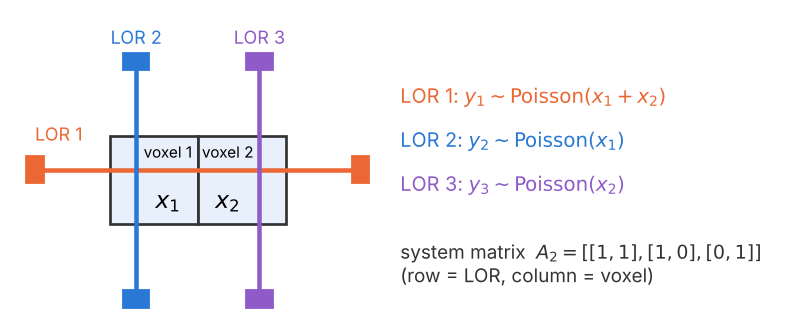

$$
\mathbf{y} \sim \mathrm{Poisson}(A_2\mathbf{x}), \qquad
A_2 = \begin{pmatrix}1 & 1\\ 1 & 0\\ 0 & 1\end{pmatrix}
\quad\Longleftrightarrow\quad
y_1 \sim \mathrm{Poisson}(x_1 + x_2), \quad y_2 \sim \mathrm{Poisson}(x_1), \quad y_3 \sim \mathrm{Poisson}(x_2) .
$$

Now there are more measurements than unknowns. The ML estimate (maximum of the Poisson log-likelihood) is still available in
closed form, but it is **non-linear** in the counts:

$$
\hat{x}_1 = \begin{cases} \dfrac{y_2\,(y_1 + y_2 + y_3)}{2\,(y_2 + y_3)} & \text{if } y_2 + y_3 > 0 \\[2ex] \dfrac{y_1}{4} & \text{if } y_2 + y_3 = 0 \end{cases}
\qquad\qquad
\hat{x}_2 = \begin{cases} \dfrac{y_3\,(y_1 + y_2 + y_3)}{2\,(y_2 + y_3)} & \text{if } y_2 + y_3 > 0 \\[2ex] \dfrac{y_1}{4} & \text{if } y_2 + y_3 = 0 \end{cases}
$$

(If LOR 2 and LOR 3 see nothing, the data cannot tell the two voxels apart and the ML estimate is the symmetric solution.)

For a non-linear estimator the expectation is **not easily calculated** analytically. Is it biased? By how much?
This is exactly where we need MC. (→ Toledo Q8)

**Our question (as in Part 1):** is $|r_1| > 0.01$ or $|r_2| > 0.01$, i.e. is the relative bias of $\hat{x}_1$ or of $\hat{x}_2$
larger than $0.01$ in magnitude (no matter whether it is positive or negative)?

As in Part 1, every code cell starts with a tag: `# [RUN]` and `# [FUNCTIONS]`: run without changes; `# [CHANGE]`: change the
variable marked with `# <-- CHANGE ME`, then run; `# [CALCULATE]`: enter your own short calculation (steps A3 and B1).

In [ ]:
# [RUN]
import time

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

# ONE random number generator for the whole notebook
rng = np.random.default_rng(seed=1)

## Functions (given)

The cell below defines the simulation and the ML estimator for **one** noise realisation, and the function
`mc_experiment_system2(x1_true, x2_true, N, rng)` that runs **one MC experiment** with $N$ realisations and returns the MC estimates
$\bar{x}_1, \bar{x}_2$ of the expectations and the sample standard deviations $s_1, s_2$ of the estimates. It processes one realisation after the other, as a real MC study of an
expensive reconstruction has to do. For large $N$ it prints its progress and the expected run time. Just run the cell.

In [ ]:
# [FUNCTIONS]
def simulate_system2(x1, x2, rng):
    """Simulate ONE noise realisation of imaging system 2.

    x1, x2: true activities of voxel 1 and voxel 2
    rng:    numpy random number generator
    returns: (y1, y2, y3), three integers (counts in LOR 1, LOR 2 and LOR 3)
    """
    y1 = rng.poisson(x1 + x2)
    y2 = rng.poisson(x1)
    y3 = rng.poisson(x2)

    return y1, y2, y3


def ml_estimator_system2(y1, y2, y3):
    """ML estimate for imaging system 2 for ONE realisation (symmetric solution if y2 + y3 = 0).

    y1, y2, y3: counts (integers)
    returns: (x1_hat, x2_hat), two numbers
    """
    if y2 + y3 == 0:
        x1_hat = y1 / 4
        x2_hat = y1 / 4
    else:
        x1_hat = y2 * (y1 + y2 + y3) / (2 * (y2 + y3))
        x2_hat = y3 * (y1 + y2 + y3) / (2 * (y2 + y3))

    return x1_hat, x2_hat


def mc_experiment_system2(x1_true, x2_true, N, rng):
    """ONE MC experiment with N realisations, one realisation after the other.

    returns: mean_x1, sd_x1, mean_x2, sd_x2
             (MC estimates of the expectations and the sample standard deviations of x1_hat and x2_hat)
    For large N, the progress and the expected total run time are printed.
    """
    sum_x1 = 0.0          # running sums S_1, Q_1, S_2, Q_2
    sum_sq_x1 = 0.0
    sum_x2 = 0.0
    sum_sq_x2 = 0.0

    start_time = time.time()

    for k in range(N):

        y1, y2, y3 = simulate_system2(x1_true, x2_true, rng)

        x1_hat, x2_hat = ml_estimator_system2(y1, y2, y3)

        sum_x1 = sum_x1 + x1_hat
        sum_sq_x1 = sum_sq_x1 + x1_hat ** 2
        sum_x2 = sum_x2 + x2_hat
        sum_sq_x2 = sum_sq_x2 + x2_hat ** 2

        # progress report after every tenth of the realisations (only for large N)
        if N >= 100_000 and (k + 1) % (N // 10) == 0:
            elapsed = time.time() - start_time
            expected_total = elapsed * N / (k + 1)
            print(f"   {k + 1:>11,} of {N:,} realisations done,  elapsed: {elapsed:6.1f} s,  expected total: {expected_total:6.1f} s")

    mean_x1 = sum_x1 / N
    mean_x2 = sum_x2 / N

    sd_x1 = np.sqrt((sum_sq_x1 - N * mean_x1 ** 2) / (N - 1))
    sd_x2 = np.sqrt((sum_sq_x2 - N * mean_x2 ** 2) / (N - 1))

    return mean_x1, sd_x1, mean_x2, sd_x2


def plot_intervals(labels, rel_bias_x1, SE_rel_bias_x1, rel_bias_x2, SE_rel_bias_x2, threshold, margin):
    """Plot the intervals rel_bias +- 2 SE (one row per MC experiment) against the tolerance band and the margin.

    labels: list of names of the MC experiments
    rel_bias_x1, SE_rel_bias_x1, rel_bias_x2, SE_rel_bias_x2: lists with one value per MC experiment
    """
    fig, ax = plt.subplots(1, 2, figsize=(11, 1.6 + 0.6 * len(labels)), layout="constrained", sharey=True)

    for j in range(2):
        ax[j].axvspan(-threshold, threshold, color="grey", alpha=0.25, label="tolerance band")
        ax[j].axvspan(threshold, threshold + margin, color="#2a78d6", alpha=0.12, label="margin")
        ax[j].axvspan(-threshold - margin, -threshold, color="#2a78d6", alpha=0.12)

    for i in range(len(labels)):
        ax[0].errorbar(rel_bias_x1[i], i, xerr=2 * SE_rel_bias_x1[i], fmt="o", color="black", capsize=5, lw=2)
        ax[1].errorbar(rel_bias_x2[i], i, xerr=2 * SE_rel_bias_x2[i], fmt="o", color="black", capsize=5, lw=2)

    ax[0].set_yticks(range(len(labels)))
    ax[0].set_yticklabels(labels)
    ax[0].set_ylim(-0.7, len(labels) - 0.3)
    ax[0].invert_yaxis()

    ax[0].set_title("x1_hat:  rel. bias +- 2 SE")
    ax[1].set_title("x2_hat:  rel. bias +- 2 SE")

    for j in range(2):
        ax[j].set_xlabel("MC estimate of the relative bias")

    handles, names = ax[0].get_legend_handles_labels()
    fig.legend(handles, names, loc="outside lower center", ncol=2, fontsize="small")

    plt.show()

# Part A: a nearly empty voxel 1, $\mathbf{x}_\text{true} = (0.8,\ 3.0)$ (about 20 min)

Here we study the object $\mathbf{x}_\text{true} = (0.8,\ 3.0)$: a nearly empty voxel 1 next to a weakly active voxel 2 (very low counts).
Be careful: for a non-linear estimator, the absolute and the relative bias can depend on $\mathbf{x}_\text{true}$. A result for one
object does not hold for another one. (In Part B we study a second object.)

## Step A1: a few realisations

We simulate 10 noise realisations, one after the other, and look at the counts and the estimates.

In [ ]:
# [RUN]
x1_true_A = 0.8
x2_true_A = 3.0


print("  k | y1  y2  y3 |  x1_hat  x2_hat")
print("----------------------------------")

for k in range(10):

    y1, y2, y3 = simulate_system2(x1_true_A, x2_true_A, rng)

    x1_hat, x2_hat = ml_estimator_system2(y1, y2, y3)

    print(f"{k:3d} | {y1:2d}  {y2:2d}  {y3:2d} | {x1_hat:7.3f} {x2_hat:7.3f}")

## Step A2: what do the estimates look like?

We simulate $N = 1000$ realisations (one after the other, storing the estimates this time, so that we can plot them) and measure
how long one realisation takes. We need this time later to plan the final MC experiment.

* top: histograms of the estimates $\hat{x}_j^{(k)}$,
* bottom: histograms of the relative bias of every single realisation, $(\hat{x}_j^{(k)} - x_j)/x_j$ (as in Part 1, step 1), with
  the tolerance band $[-0.01, 0.01]$.

The cell also prints the MC estimates of the expectations and of the relative biases with their SEs.

In [ ]:
# [RUN]
N_A = 1000


x1_hat_all_A = np.zeros(N_A)
x2_hat_all_A = np.zeros(N_A)

start_time = time.time()

for k in range(N_A):

    y1, y2, y3 = simulate_system2(x1_true_A, x2_true_A, rng)

    x1_hat_all_A[k], x2_hat_all_A[k] = ml_estimator_system2(y1, y2, y3)

time_per_realisation = (time.time() - start_time) / N_A


# MC estimates of the expectations and their SEs
mean_x1_A = np.mean(x1_hat_all_A)
mean_x2_A = np.mean(x2_hat_all_A)

SE_mean_x1_A = np.std(x1_hat_all_A, ddof=1) / np.sqrt(N_A)
SE_mean_x2_A = np.std(x2_hat_all_A, ddof=1) / np.sqrt(N_A)

# relative bias of every single realisation, its mean and the SE of the mean
rel_bias_single_x1_A = (x1_hat_all_A - x1_true_A) / x1_true_A
rel_bias_single_x2_A = (x2_hat_all_A - x2_true_A) / x2_true_A

rel_bias_x1_A = np.mean(rel_bias_single_x1_A)
rel_bias_x2_A = np.mean(rel_bias_single_x2_A)

SE_rel_bias_x1_A = SE_mean_x1_A / x1_true_A
SE_rel_bias_x2_A = SE_mean_x2_A / x2_true_A


print(f"time per realisation: {1e6 * time_per_realisation:.1f} microseconds")
print()
print(f"x1_hat: MC mean = {mean_x1_A:.3f},  SE = {SE_mean_x1_A:.3f}   |  rel. bias = {rel_bias_x1_A:+.3f},  SE_rel_bias_x1 = {SE_rel_bias_x1_A:.3f}")
print(f"x2_hat: MC mean = {mean_x2_A:.3f},  SE = {SE_mean_x2_A:.3f}   |  rel. bias = {rel_bias_x2_A:+.3f},  SE_rel_bias_x2 = {SE_rel_bias_x2_A:.3f}")


fig, ax = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")

# bins of width 0.5, centred on 0, 0.5, 1, ... (many estimates are multiples of 0.5)
bins_x1 = np.arange(-0.25, 6.0, 0.5)
bins_x2 = np.arange(-0.25, 9.0, 0.5)

# top row: the estimates
ax[0, 0].hist(x1_hat_all_A, bins=bins_x1, color="#2a78d6")
ax[0, 1].hist(x2_hat_all_A, bins=bins_x2, color="#eb6834")

ax[0, 0].set_xlabel("x1_hat")
ax[0, 1].set_xlabel("x2_hat")

# bottom row: the relative bias of every single realisation
ax[1, 0].hist(rel_bias_single_x1_A, bins=(bins_x1 - x1_true_A) / x1_true_A, color="#2a78d6")
ax[1, 1].hist(rel_bias_single_x2_A, bins=(bins_x2 - x2_true_A) / x2_true_A, color="#eb6834")

for j in range(2):
    ax[1, j].axvspan(-0.01, 0.01, color="black", alpha=0.6, label="tolerance band [-0.01, 0.01]")
    ax[1, j].set_xlabel("relative bias of a single realisation")
    ax[1, j].legend(fontsize="small")

for i in range(2):
    for j in range(2):
        ax[i, j].set_ylabel("number of realisations")

plt.show()

**Reflection.** From these histograms we can guess neither the size nor even the sign of the bias. The distributions are very
skewed, so the mean is not where the histogram "looks" centred. More importantly, the bias we
are interested in (of the order of $0.01$) is tiny compared to the spread of the single realisations (relative standard deviation of
the order of $1$): the tolerance band is a thin line in the bottom plots, and with $N = 1000$ the interval $\hat{r}_j \pm 2\,\mathrm{SE}$
is much wider than the band. We need far more realisations, and a plan for how many.

## Step A3: pilot run and planning of $N$ (think before you run!)

We use the decision rule and the planning rule of **Part 1, step 6**: tolerance $0.01$, margin $m = 0.005$, interval
$\hat{r}_j \pm 2\,\mathrm{SE}(\hat{r}_j)$, and a reliable decision if $4\,\mathrm{SE}(\hat{r}_j) \le m$, which gives
$N \ge \big(4\,(s_j/x_j)/m\big)^2$.

The **true relative bias is unknown**. The pilot run below ($N = 1000$) prints the MC estimate of the mean and the sample standard
deviation $s_j$ of both estimators. **Estimate** how many realisations the final run needs, and how long it will take (time per
realisation: step A2). Enter your calculation in the `[CALCULATE]` cell below.

In [ ]:
# [RUN]
threshold = 0.01     # tolerance for the relative bias
margin = 0.005       # margin (Part 1, step 6)

In [ ]:
# [RUN]
N_pilot_A = 1000


mean_x1_pilot_A, sd_x1_pilot_A, mean_x2_pilot_A, sd_x2_pilot_A = mc_experiment_system2(x1_true_A, x2_true_A, N_pilot_A, rng)


print(f"Part A, pilot run, N = {N_pilot_A}")
print(f"   x1_hat: MC estimate of the mean = {mean_x1_pilot_A:.4f},  sample std. dev. s_1 = {sd_x1_pilot_A:.4f}   (true x1 = {x1_true_A})")
print(f"   x2_hat: MC estimate of the mean = {mean_x2_pilot_A:.4f},  sample std. dev. s_2 = {sd_x2_pilot_A:.4f}   (true x2 = {x2_true_A})")
print()
print(f"time per realisation (step A2): {1e6 * time_per_realisation:.1f} microseconds")

In [ ]:
# [CALCULATE] your short calculation of the needed N for Part A (planning rule of Part 1, step 6)
# available: sd_x1_pilot_A, sd_x2_pilot_A (pilot run), x1_true_A, x2_true_A, margin, time_per_realisation

## Step A4: the final run

Set `N_final_A` to your choice and run the cell: **one** final MC experiment. Choose $N$ **as small as possible** (the run time grows
proportionally to $N$), but large enough. The cell first prints the expected run time. You can stop a cell that runs too long with
the stop button ■ (or "Kernel → Interrupt").

In [ ]:
# [CHANGE]
N_final_A = 1000       # <-- CHANGE ME: your choice


print(f"N_final_A = {N_final_A:,}:  expected run time {N_final_A * time_per_realisation:.1f} s")
print()

mean_x1_final_A, sd_x1_final_A, mean_x2_final_A, sd_x2_final_A = mc_experiment_system2(x1_true_A, x2_true_A, N_final_A, rng)


rel_bias_x1_final_A = (mean_x1_final_A - x1_true_A) / x1_true_A                     # MC estimate of the relative bias
rel_bias_x2_final_A = (mean_x2_final_A - x2_true_A) / x2_true_A

SE_rel_bias_x1_final_A = sd_x1_final_A / (x1_true_A * np.sqrt(N_final_A))      # its standard error
SE_rel_bias_x2_final_A = sd_x2_final_A / (x2_true_A * np.sqrt(N_final_A))


print()
print(f"x1: rel. bias = {rel_bias_x1_final_A:+.5f},  4 * SE_rel_bias_x1 = {4 * SE_rel_bias_x1_final_A:.5f}"
      f"  ->  interval [{rel_bias_x1_final_A - 2 * SE_rel_bias_x1_final_A:+.5f}, {rel_bias_x1_final_A + 2 * SE_rel_bias_x1_final_A:+.5f}]")
print(f"x2: rel. bias = {rel_bias_x2_final_A:+.5f},  4 * SE_rel_bias_x2 = {4 * SE_rel_bias_x2_final_A:.5f}"
      f"  ->  interval [{rel_bias_x2_final_A - 2 * SE_rel_bias_x2_final_A:+.5f}, {rel_bias_x2_final_A + 2 * SE_rel_bias_x2_final_A:+.5f}]")
print(f"margin m = {margin}")

plot_intervals([f"final, N = {N_final_A:,}"], [rel_bias_x1_final_A], [SE_rel_bias_x1_final_A], [rel_bias_x2_final_A], [SE_rel_bias_x2_final_A],
               threshold, margin)

**Reflection.** Check for both estimators whether the interval lies completely outside or completely inside the tolerance band, and
whether $4\,\mathrm{SE} \le m$ is reached for the estimator that matters. Think about what an $N$ ten times smaller would have shown,
and what an $N$ ten or a hundred times larger would have cost in run time and gained in insight. (→ Toledo Q9, Q10, Q11)

---
# Part B: a nearly empty voxel 2, $\mathbf{x}_\text{true} = (8.5,\ 0.08)$ (about 15 min)

Now we repeat the study for a different object, $\mathbf{x}_\text{true} = (8.5,\ 0.08)$: an active voxel 1 next to a nearly empty
voxel 2. Since the bias of a non-linear estimator can depend on $\mathbf{x}_\text{true}$, we cannot reuse the result of Part A.
Again the true relative bias is unknown. Repeat the workflow of steps A3 and A4.

## Step B1: pilot run and planning of $N$

Run the pilot run, then estimate $N$ (and the run time) in the `[CALCULATE]` cell below, as in step A3.

In [ ]:
# [RUN]
x1_true_B = 8.5
x2_true_B = 0.08

N_pilot_B = 1000


mean_x1_pilot_B, sd_x1_pilot_B, mean_x2_pilot_B, sd_x2_pilot_B = mc_experiment_system2(x1_true_B, x2_true_B, N_pilot_B, rng)


print(f"Part B, pilot run, N = {N_pilot_B}")
print(f"   x1_hat: MC estimate of the mean = {mean_x1_pilot_B:.4f},  sample std. dev. s_1 = {sd_x1_pilot_B:.4f}   (true x1 = {x1_true_B})")
print(f"   x2_hat: MC estimate of the mean = {mean_x2_pilot_B:.4f},  sample std. dev. s_2 = {sd_x2_pilot_B:.4f}   (true x2 = {x2_true_B})")
print()
print(f"time per realisation (step A2): {1e6 * time_per_realisation:.1f} microseconds")

In [ ]:
# [CALCULATE] your short calculation of the needed N for Part B (planning rule of Part 1, step 6)
# available: sd_x1_pilot_B, sd_x2_pilot_B (pilot run), x1_true_B, x2_true_B, margin, time_per_realisation

## Step B2: the final run

Set `N_final_B` to your choice and run the cell (again: as small as possible, but large enough).

In [ ]:
# [CHANGE]
N_final_B = 1000       # <-- CHANGE ME: your choice


print(f"N_final_B = {N_final_B:,}:  expected run time {N_final_B * time_per_realisation:.1f} s")
print()

mean_x1_final_B, sd_x1_final_B, mean_x2_final_B, sd_x2_final_B = mc_experiment_system2(x1_true_B, x2_true_B, N_final_B, rng)


rel_bias_x1_final_B = (mean_x1_final_B - x1_true_B) / x1_true_B                     # MC estimate of the relative bias
rel_bias_x2_final_B = (mean_x2_final_B - x2_true_B) / x2_true_B

SE_rel_bias_x1_final_B = sd_x1_final_B / (x1_true_B * np.sqrt(N_final_B))      # its standard error
SE_rel_bias_x2_final_B = sd_x2_final_B / (x2_true_B * np.sqrt(N_final_B))


print()
print(f"x1: rel. bias = {rel_bias_x1_final_B:+.5f},  4 * SE_rel_bias_x1 = {4 * SE_rel_bias_x1_final_B:.5f}"
      f"  ->  interval [{rel_bias_x1_final_B - 2 * SE_rel_bias_x1_final_B:+.5f}, {rel_bias_x1_final_B + 2 * SE_rel_bias_x1_final_B:+.5f}]")
print(f"x2: rel. bias = {rel_bias_x2_final_B:+.5f},  4 * SE_rel_bias_x2 = {4 * SE_rel_bias_x2_final_B:.5f}"
      f"  ->  interval [{rel_bias_x2_final_B - 2 * SE_rel_bias_x2_final_B:+.5f}, {rel_bias_x2_final_B + 2 * SE_rel_bias_x2_final_B:+.5f}]")
print(f"margin m = {margin}")

plot_intervals([f"final, N = {N_final_B:,}"], [rel_bias_x1_final_B], [SE_rel_bias_x1_final_B], [rel_bias_x2_final_B], [SE_rel_bias_x2_final_B],
               threshold, margin)

**Reflection.** Note your conclusion for both estimators in Part B and which of the two determines the number of realisations.
Although both relative biases turn out to be below $0.01$, Part B needs more realisations than Part A: compare $s_j/x_j$ of the nearly
empty voxel in Part A and Part B, and remember that showing a bias **below** the threshold needs the same precision (margin) as showing
one above it. Also think about what you would have concluded with the $N$ of Part A. (→ Toledo Q12, Q13)

## Reflection

* Here one realisation takes a few microseconds. In a real MC study of an image reconstruction method, one realisation is a full
  reconstruction and can take a minute. Then $N = 10^6$ realisations take about **two years** of computing time, and a careless
  choice of $N$ that is ten times too large takes about twenty years.
* This is why we always start with a cheap pilot run and **plan** $N$ before the expensive run.
* In Part 1 we could afford to repeat the whole MC experiment many times to see the spread of $\hat{r}_j$ (histograms). Here, and in
  practice, we run it **once**, and the SE of that single run is all we know about its uncertainty.

(→ Toledo Q14: describe in your own words what you learned in this session.)

**Bonus questions** (→ Toledo, Bonus 1 and Bonus 2): add your own cells below Step B2, using the given function `mc_experiment_system2`.